In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# adjust this csv file path as required depending on the local directory structure
df = pd.read_csv("/clean_london_house_prices.csv")

df['date'] = pd.to_datetime(df['date'])

df.head()

,date,area,average_price,code,houses_sold,no_of_crimes,borough_flag,cpi_index_2015_100,cpi_yoy_pct,cpi_mom_pct,bank_rate_monthly_avg,year,month,quarter
0,2001-01-01,barking and dagenham,82343,E09000002,215.0,1771.0,1,66.179174,2.708460,-0.633005,6.000000,2001,1,1
1,2001-02-01,barking and dagenham,83266,E09000002,238.0,1600.0,1,66.522325,2.678571,0.518519,5.812500,2001,2,1
2,2001-03-01,barking and dagenham,84058,E09000002,274.0,1759.0,1,66.600760,2.258016,0.117907,5.750000,2001,3,1
3,2001-04-01,barking and dagenham,83965,E09000002,241.0,1643.0,1,66.953715,1.773472,0.529957,5.533333,2001,4,2
4,2001-05-01,barking and dagenham,85124,E09000002,283.0,1809.0,1,67.375301,2.049302,0.629668,5.322581,2001,5,2


In [33]:
df['date'] = pd.to_datetime(df['date'])

df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['quarter'] = df['date'].dt.quarter
df['month_name'] = df['date'].dt.month_name().str[:3]

In [34]:
print("Dataset shape:", df.shape)
print("\nDate range:", df['date'].min(), "to", df['date'].max())
print("\nNumber of areas:", df['area'].nunique())
print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

display(
    df[
        [
            'average_price',
            'houses_sold',
            'cpi_index_2015_100',
            'bank_rate_monthly_avg'
        ]
    ].describe().T
)

Dataset shape: (7375, 15)

Date range: 2001-01-01 00:00:00 to 2019-11-01 00:00:00

Number of areas: 33

Missing values:


,0
date,0
area,0
average_price,0
code,0
houses_sold,0
no_of_crimes,0
borough_flag,0
cpi_index_2015_100,0
cpi_yoy_pct,0
cpi_mom_pct,0



Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
average_price,7375.0,348548.701424,188272.218176,82343.000000,225163.000000,296068.000000,415970.000000,1.463378e+06
houses_sold,7375.0,307.768000,140.912424,2.000000,207.000000,283.000000,390.000000,9.630000e+02
cpi_index_2015_100,7375.0,87.535761,13.944828,66.179174,74.493239,86.170187,99.631521,1.128281e+02
bank_rate_monthly_avg,7375.0,2.262911,2.068133,0.250000,0.500000,0.750000,4.500000,6.000000e+00


###  Average London House Prices Over Time

Start date: 2001-01-01 00:00:00
End date: 2019-11-01 00:00:00
Number of areas: 33
Number of rows: 7375


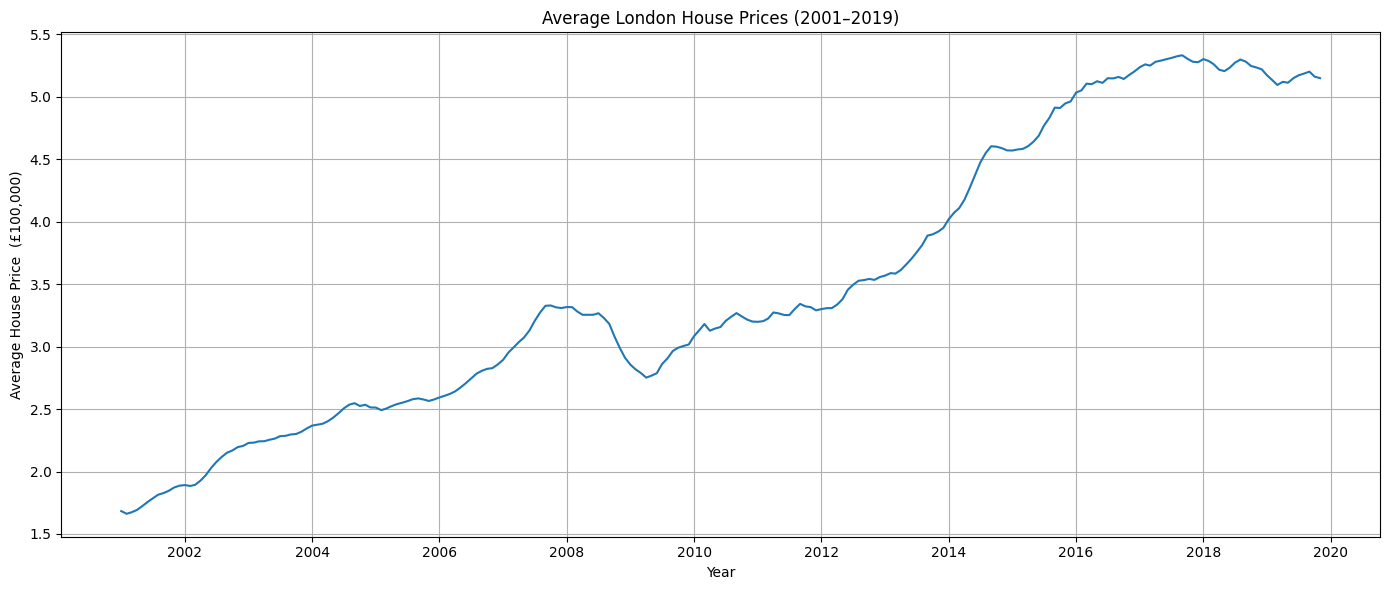

In [35]:
monthly_price = df.groupby('date')['average_price'].mean() / 100000

plt.figure(figsize=(14,6))
plt.plot(monthly_price)

print("Start date:", df['date'].min())
print("End date:", df['date'].max())
print("Number of areas:", df['area'].nunique())
print("Number of rows:", len(df))

start_year = df['date'].dt.year.min()
end_year = df['date'].dt.year.max()

plt.title(
    f'Average London House Prices ({start_year}–{end_year})'
)


plt.xlabel('Year')
plt.ylabel('Average House Price  (x £100,000)')

plt.grid(True)

plt.tight_layout()
plt.show()


This shows a substantial increase in London house prices between 1995 and 2020. Although temporary slowdowns are visible during economic downturns, the overall trend remains strongly upward. This indicates long-term growth in the London housing market.

### Top 10 Most Expensive Areas

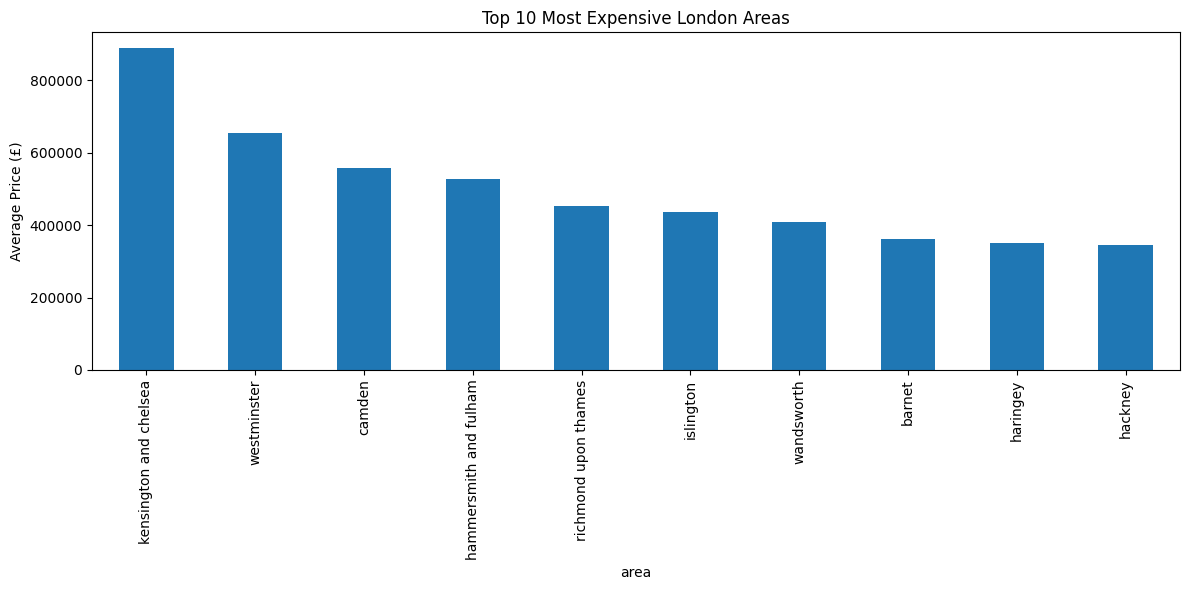

In [36]:
top10 = (
    df.groupby('area')['average_price']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12,6))
top10.plot(kind='bar')

plt.title('Top 10 Most Expensive London Areas')
plt.ylabel('Average Price (£)')
plt.tight_layout()
plt.show()

Significant differences exist between London areas. Central locations generally exhibit substantially higher average property values compared with outer regions, demonstrating spatial inequality within the housing market.

### Top 10 Least Expensive London Areas

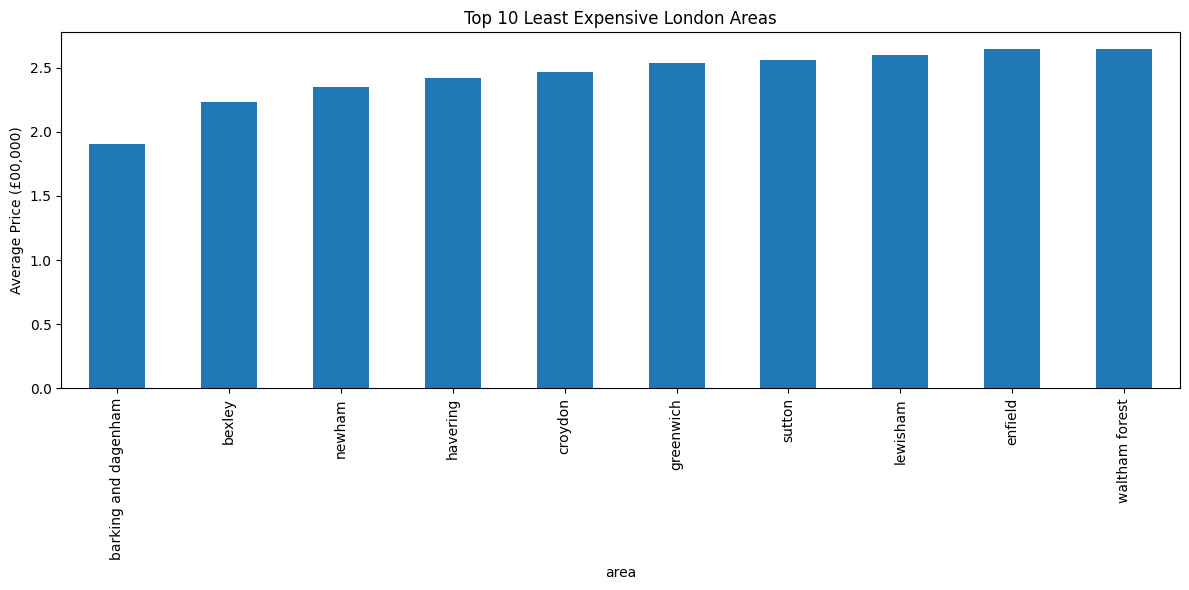

In [37]:
bottom10 = (
    df.groupby('area')['average_price']
    .mean()
    .sort_values()
    .head(10)/ 100000
)

plt.figure(figsize=(12,6))
bottom10.plot(kind='bar')

plt.title('Top 10 Least Expensive London Areas')
plt.ylabel('Average Price (£00,000)')
plt.tight_layout()
plt.show()

The least expensive areas generally have lower long-term average property prices than central and premium London boroughs. This demonstrates substantial geographical variation in the London housing market. However, these averages combine observations from different years, so part of the variation may reflect both location and changes in prices over time.

### Monthly Houses Sold

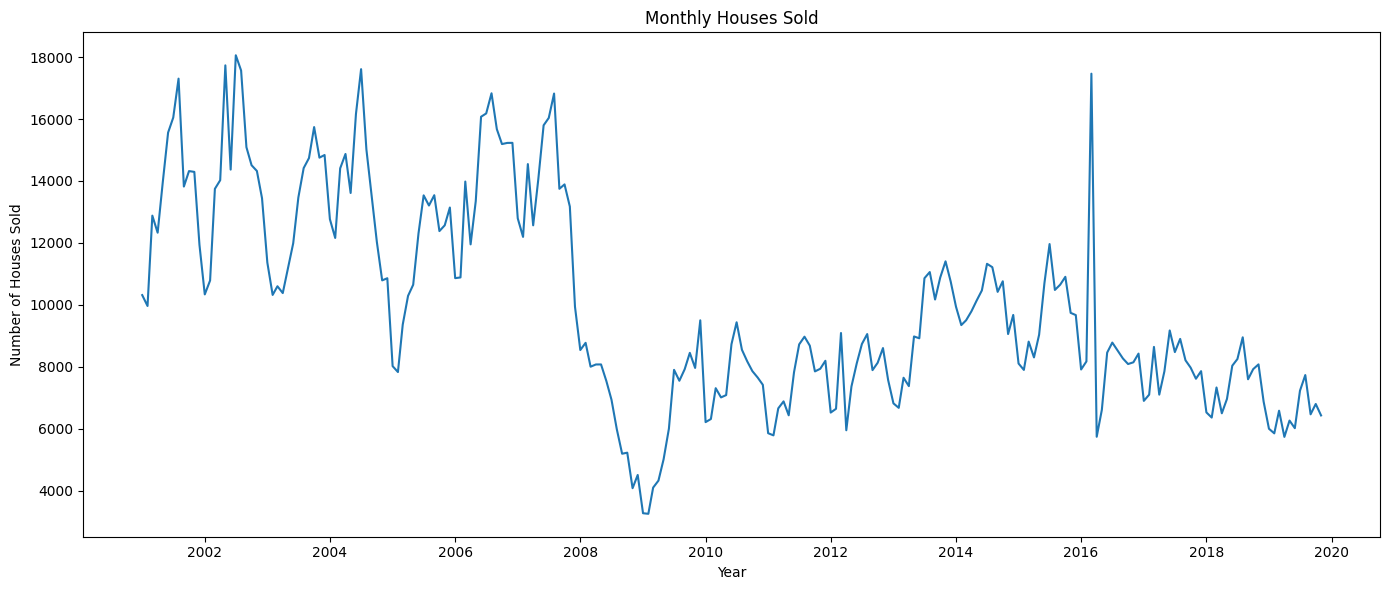

In [38]:
sales = df.groupby('date')['houses_sold'].sum()

plt.figure(figsize=(14,6))
plt.plot(sales)

plt.title('Monthly Houses Sold')
plt.xlabel('Year')
plt.ylabel('Number of Houses Sold')

plt.tight_layout()
plt.show()

Market activity fluctuated substantially across the period. Periods of economic uncertainty appear associated with lower transaction volumes.

### Consumer Price Index Over Time

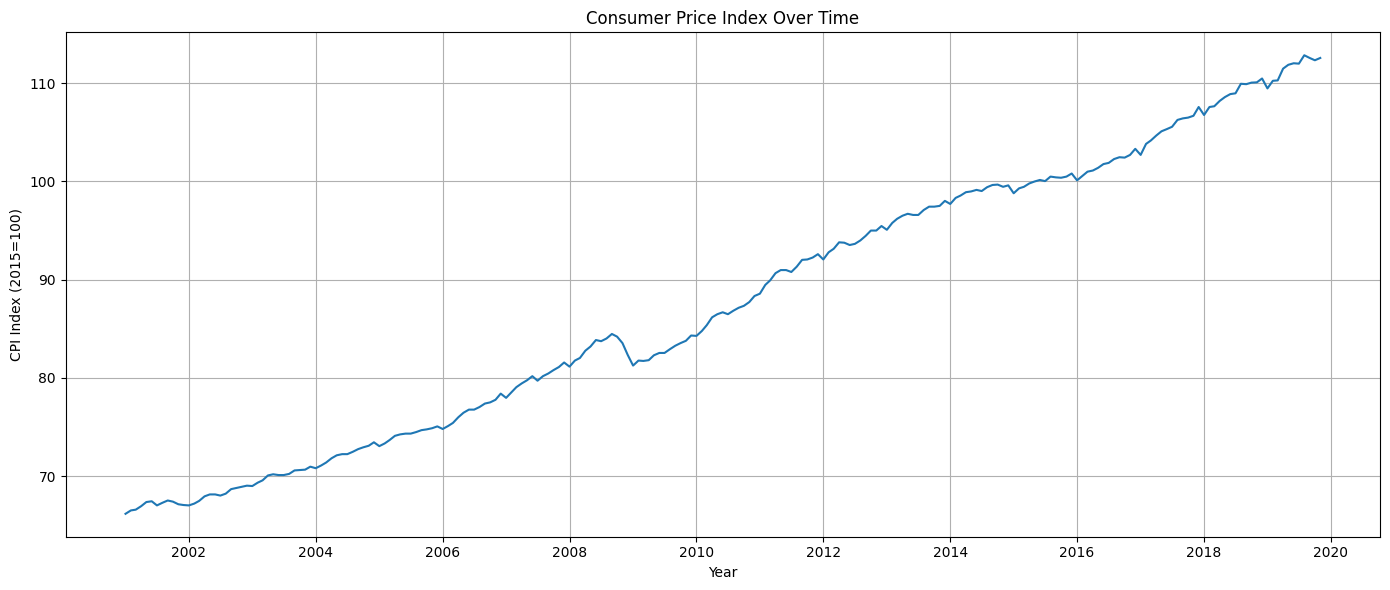

In [60]:
cpi = df.groupby('date')['cpi_index_2015_100'].mean()

plt.figure(figsize=(14,6))
plt.plot(cpi)

plt.title('Consumer Price Index Over Time')
plt.ylabel('CPI Index (2015=100)')
plt.xlabel('Year')
plt.grid(True)
plt.tight_layout()
plt.show()

CPI exhibited a long-term upward trend, reflecting inflationary pressures in the UK economy. Inflation may contribute to rising nominal property values.

### Bank of England Bank Rate


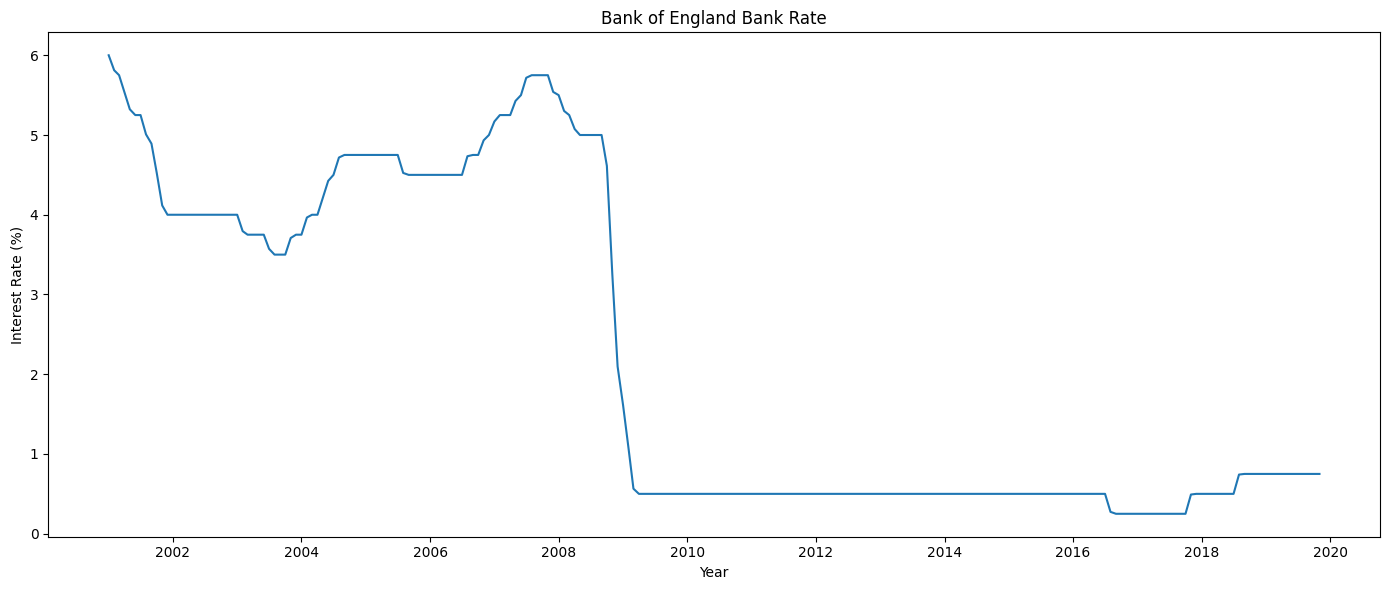

In [61]:
rate = df.groupby('date')['bank_rate_monthly_avg'].mean()

plt.figure(figsize=(14,6))
plt.plot(rate)

plt.title('Bank of England Bank Rate')
plt.ylabel('Interest Rate (%)')
plt.xlabel('Year')
plt.tight_layout()
plt.show()

Interest rates experienced major changes throughout the study period. Lower interest rates generally improve mortgage affordability and may stimulate housing demand.

###  Correlation Matrix of Housing and Economic Variables

In [41]:
corr_cols = [
    'average_price',
    'houses_sold',
    'cpi_index_2015_100',
    'bank_rate_monthly_avg'
]

corr = df[corr_cols].corr()


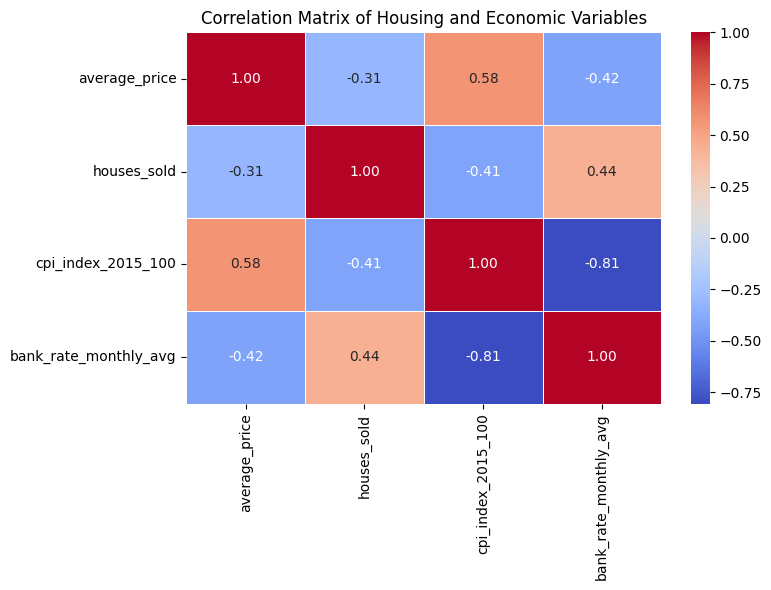

In [42]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix of Housing and Economic Variables')
plt.tight_layout()
plt.show()

### Average House Price by Calendar Month

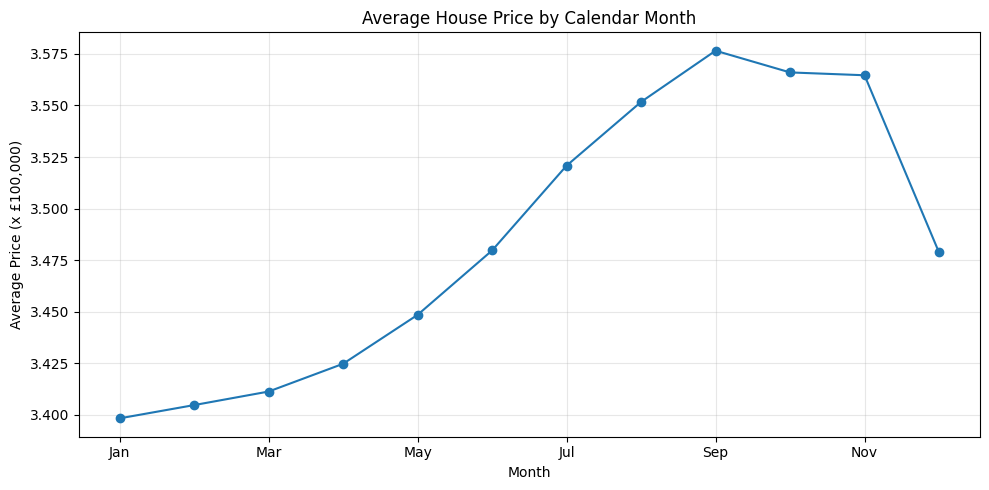

In [ ]:
#Investigate seasonality
month_order = [
    'Jan', 'Feb', 'Mar', 'Apr',
    'May', 'Jun', 'Jul', 'Aug',
    'Sep', 'Oct', 'Nov', 'Dec'
]

monthly_avg = (
    df.groupby('month_name')['average_price']
      .mean()
      .reindex(month_order) / 100000
)

plt.figure(figsize=(10, 5))
monthly_avg.plot(marker='o')

plt.title('Average House Price by Calendar Month')
plt.xlabel('Month')
plt.ylabel('Average Price (x £100,000)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Seasonal variation is visible across months, suggesting that housing transactions and pricing may be influenced by recurring annual patterns.

###  Average Monthly House-Price Change by Calendar Month

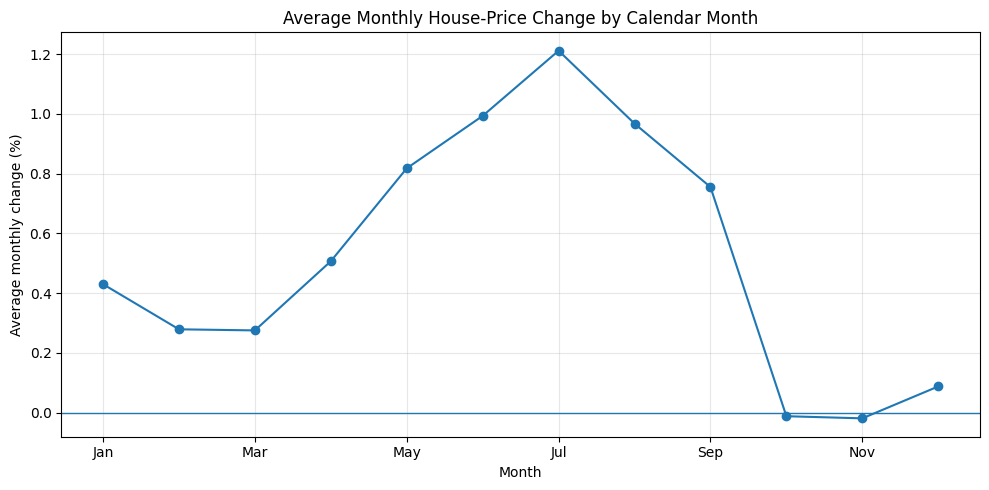

In [ ]:
seasonal_growth = (
    df.sort_values(['area', 'date'])
      .assign(
          monthly_change=lambda x:
          x.groupby('area')['average_price'].pct_change() * 100
      )
      .groupby('month_name')['monthly_change']
      .mean()
      .reindex(month_order)
)
#each borough's month-to-month change is calculated independently

plt.figure(figsize=(10, 5))
seasonal_growth.plot(marker='o')

plt.axhline(0, linewidth=1)
plt.title('Average Monthly House-Price Change by Calendar Month')
plt.xlabel('Month')
plt.ylabel('Average monthly change (%)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## **Before vs After 2008 Financial Crisis**

###  London Housing Market Before and After the 2008 Crisis

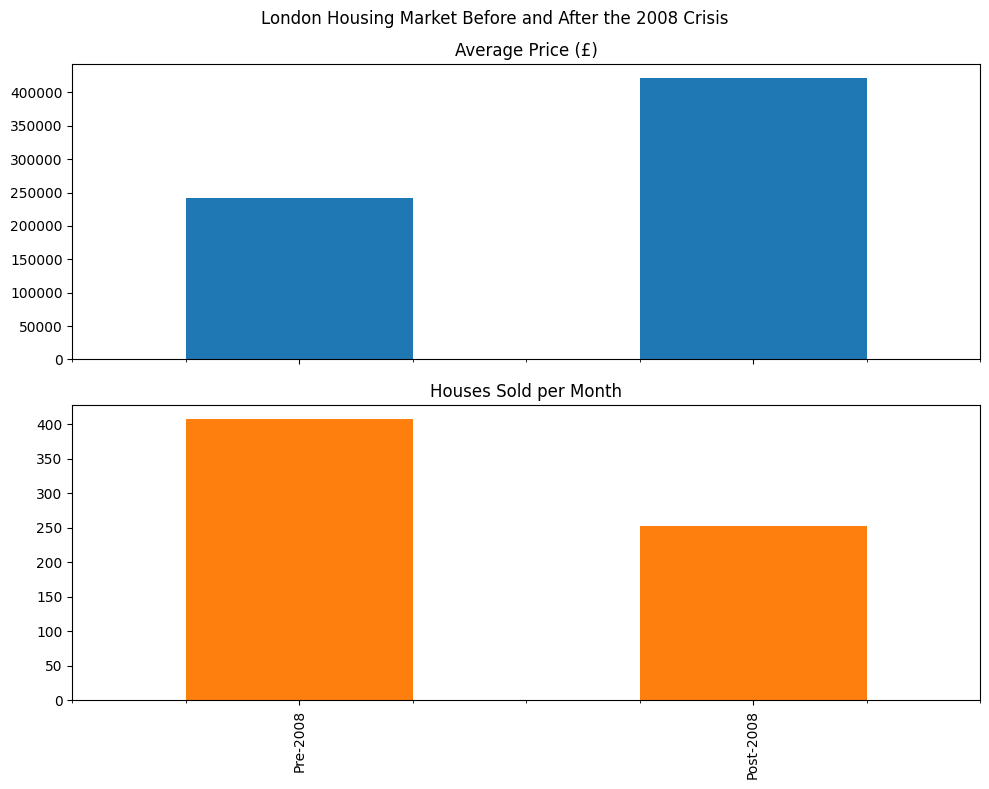

In [54]:
pre2008 = df[df['year'] <= 2007]
post2008 = df[df['year'] >= 2009]

pre_crisis = df[df['year'] <= 2007]
post_crisis = df[df['year'] >= 2009]


comparison = pd.DataFrame({
    'Pre-2008': [
        pre2008['average_price'].mean(),
        pre2008['houses_sold'].mean()
    ],
    'Post-2008': [
        post2008['average_price'].mean(),
        post2008['houses_sold'].mean()
    ]
},
index=['Average Price (£)','Houses Sold per Month'])

comparison.T.plot(
    kind='bar',
    subplots=True,
    figsize=(10, 8),
    legend=False
)

plt.suptitle('London Housing Market Before and After the 2008 Crisis')
plt.tight_layout()
plt.show()





Average property prices were approximately 70% higher in the post-2008 period, while average transaction volume was approximately 39% lower. These descriptive differences suggest a change in market conditions.

The descriptive comparison shows substantially higher prices and lower average transaction volume in the post-2008 observations, but it cannot establish a causal effect of the financial crisis

In [46]:
price_change = (
    (412405.309581 - 242512.638167)
    / 242512.638167
) * 100

sales_change = (
    (248.015207 - 406.989538)
    / 406.989538
) * 100

print( price_change)
print( sales_change)

70.05518256620006
-39.061036256907414


### Distribution of House Prices

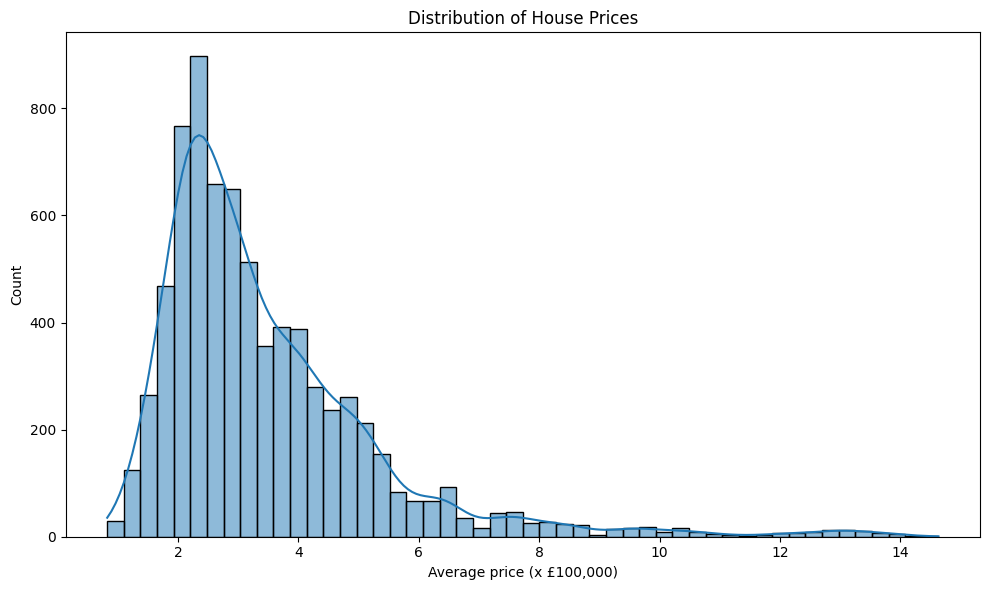

In [58]:
plt.figure(figsize=(10,6))

sns.histplot(
    df['average_price'] /100000,
    bins=50,
    kde=True
)

plt.title('Distribution of House Prices')
plt.xlabel('Average price (x £100,000)')

plt.tight_layout()
plt.show()

The distribution of average house prices is positively skewed, with most observations concentrated in the lower and middle price ranges and a smaller number of very expensive observations forming a long right tail. This suggests that the mean may be influenced by premium areas and later years. A logarithmic transformation of average price may therefore be tested during modelling.

### House Price Outliers

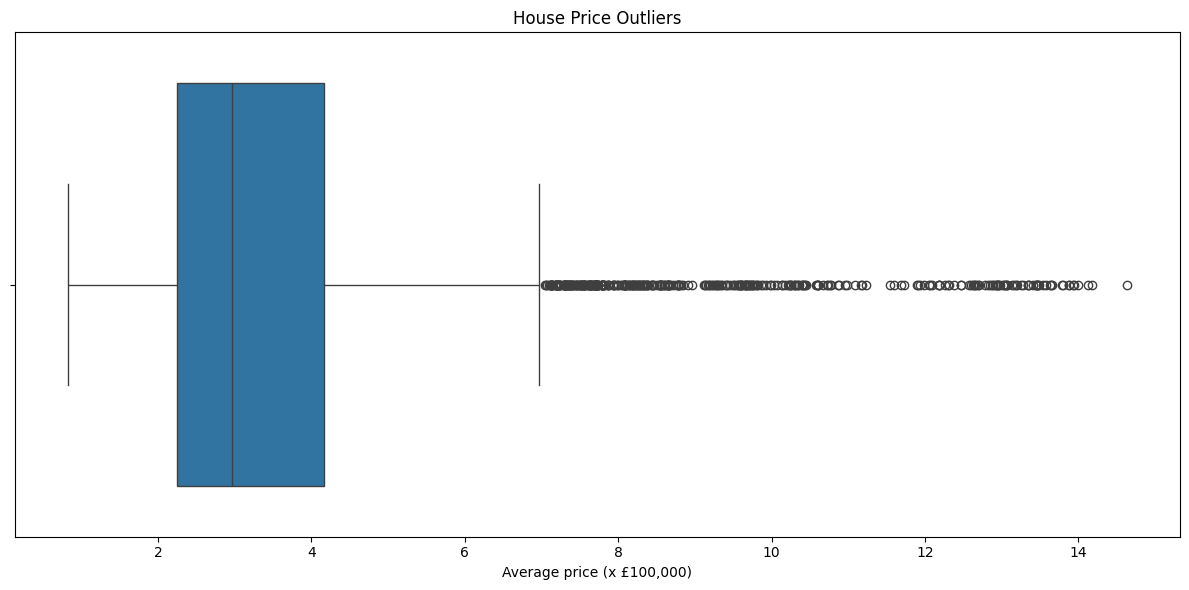

In [59]:
plt.figure(figsize=(12,6))

sns.boxplot(
    x=df['average_price'] /100000
)

plt.title('House Price Outliers')
plt.xlabel('Average price (x £100,000)')
plt.tight_layout()
plt.show()

The distribution of average house prices is positively skewed, with a substantial number of high-price observations above the upper whisker. These observations are likely to reflect genuine price differences across London boroughs, particularly premium boroughs, rather than data errors. Therefore, they were retained unless further data-quality checks indicated otherwise.

I retained plausible high-value observations because in the London housing market they may represent genuine premium boroughs rather than measurement errors.

###  Average House Price vs CPI

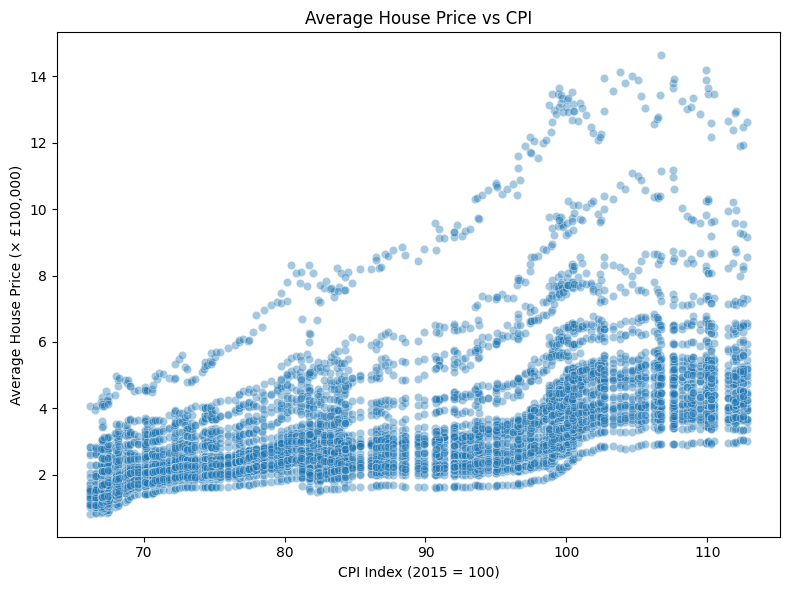

In [49]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='cpi_index_2015_100',
    y=df['average_price'] / 100000,
    alpha=0.4
)

plt.title('Average House Price vs CPI')
plt.xlabel('CPI Index (2015 = 100)')
plt.ylabel('Average House Price (× £100,000)')

plt.tight_layout()
plt.show()

The scatter plot is expected to show a positive association between CPI and nominal house prices. However, both variables generally increase over time, so this relationship may be partly driven by their common time trend. Time-aware modelling is required before drawing stronger conclusions.

So a scatterplot alone cannot establish that higher CPI directly causes higher house prices.

###  Average House Price vs Bank Rate

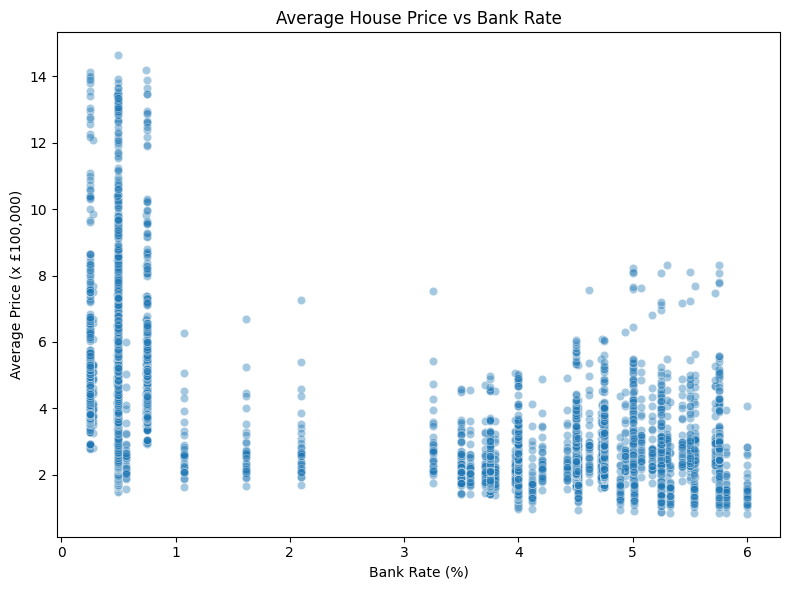

In [50]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='bank_rate_monthly_avg',
    y=df['average_price'] / 100000,
    alpha=0.4
)

plt.title('Average House Price vs Bank Rate')
plt.xlabel('Bank Rate (%)')
plt.ylabel('Average Price (x £100,000)')
plt.tight_layout()
plt.show()


Bank Rate up -->  Mortgage Cost up --> so  Affordability down


The relationship between Bank Rate and house prices may be non-linear and affected by economic periods. Lower rates can improve mortgage affordability, but a simple scatter plot cannot isolate this effect from inflation, income, market expectations or long-term price growth.

###  Housing Transactions vs Average Price

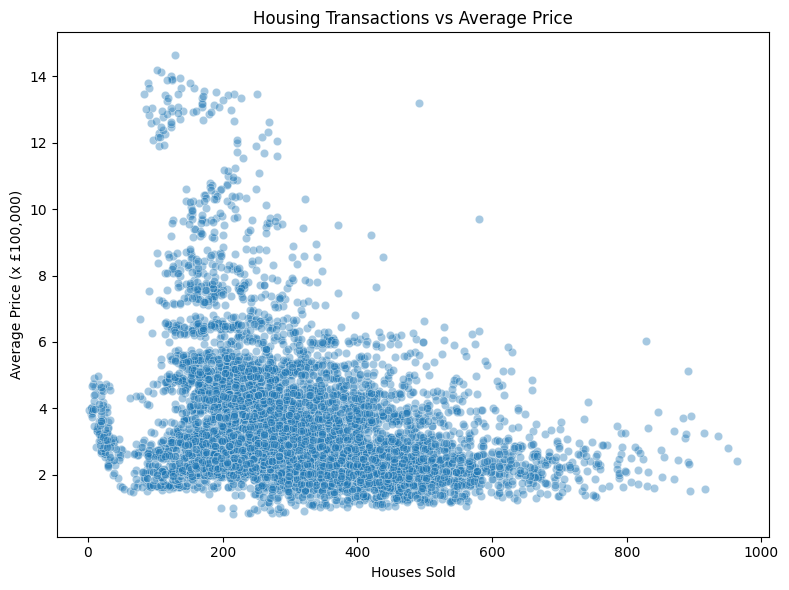

In [51]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='houses_sold',
    y=df['average_price'] / 100000,
    alpha=0.4
)

plt.title('Housing Transactions vs Average Price')
plt.xlabel('Houses Sold')
plt.ylabel('Average Price (x £100,000)')
plt.tight_layout()
plt.show()

The scatter plot shows the relationship between housing market activity and average property prices. The relationship does not appear perfectly linear, suggesting that transaction volume alone is unlikely to explain house prices and should be considered alongside macroeconomic variables during modelling.

The exploratory analysis shows that there is a lot of growth in house prices in London over time, there are large variations in prices between regions and transaction volume fell during parts of the study period, and there are clear changes in the Bank Rate and CPI. House prices are skewed and have real high value observations where they reside in the better neighborhoods and where they were built later. But there is a positive relationship between CPI and nominal house prices, which might partly be due to a common time trend. Forecasting models with time (time-synchronous) aspects seem to be more complicated in the relationships between Bank Rate and transaction volume. The results justify the use of these area characteristics, historical price data, the CPI, the Bank Rate and housing-market activity in the feature-engineering and modelling phases.

The most important overall EDA findings
 
1. House prices rise strongly over time.
2. Large differences exist between London boroughs.
3. Housing transaction volumes fluctuate considerably over time.
4. CPI generally increases over the study period.
5. Bank Rate changes substantially across economic periods.
6. House-price observations are positively/right skewed with legitimate high-value observations.
7. Relationships between price and economic variables are complex and affected by time.